# RL-Driven Quantum Pulse Optimization
### An Educational Tutorial for Superconducting Qubit Control

---

**Author:** Quantum Control Engineering Portfolio Project  
**Stack:** QuTiP · Gymnasium · Stable-Baselines3 (PPO) · SciPy (GRAPE baselines + statistics) · NumPy · Matplotlib

---

## What We Are Building

We train a **Reinforcement Learning agent** to find an I/Q microwave pulse shape that drives a **3-level transmon** (|0⟩, |1⟩, and the leakage level |2⟩) from the ground state |0⟩ to the excited state |1⟩ in minimum time, maximizing fidelity under decoherence, drive leakage, finite control bandwidth, and unknown per-episode miscalibration. (This measures a single input-state transfer, |0⟩→|1⟩, not full average gate fidelity over all inputs — see `SCIENCE.md`, Section 3.)

The real question this project answers isn't "can RL reach high fidelity" — it's **does RL's apparent advantage over gradient-based optimal control (GRAPE) survive the constraint that a real gate has to run open-loop?** Measured, not assumed, the answer is **no**: GRAPE beats every physically deployable version of the RL policy. Four things make that a measured answer, not a claim:

1. **Leakage.** Driving |0⟩↔|1⟩ also weakly drives |1⟩↔|2⟩ — the agent has a second ("Q") control channel and must learn to suppress leakage itself. (It does *not* rediscover the textbook DRAG correction — Section 8 shows what it does instead, after validating the detection method against a known DRAG pulse. Leakage turns out to be the one advantage that *does* survive the open-loop constraint below.)
2. **Two GRAPE baselines.** `grape_baseline.py` implements nominal GRAPE (optimized for the known, uncalibrated qubit) *and* ensemble/robust GRAPE (optimized for average performance over the same miscalibration distribution RL trains on) — comparing RL only against the nominal-only baseline isn't a fair fight.
3. **A mechanism test.** The agent observes exact, noiseless mid-gate simulator state — real qubit readout cannot do this (destructive, hundreds of ns to µs, against a 10 ns gate). So any RL-vs-GRAPE gap could be "a more robust waveform" or "exploiting information no open-loop pulse could use." Section 8 settles this by freezing the trained policy into a fixed pulse and re-evaluating it exactly like GRAPE — **the frozen pulse loses to GRAPE**, which is why the headline answer above is "no."
4. **Five seeds, paired evaluation.** Every controller — naive, GRAPE, ensemble-GRAPE, RL (live), RL (frozen) — is optimized/trained across 5 independent seeds and evaluated on an identical set of paired miscalibration draws, with mean ± std reported across seeds and paired significance tests.

### Roadmap
1. Physics of a 3-level transmon (leakage, anharmonicity)
2. Open quantum systems: the Lindblad master equation (T1, T2, leakage decay)
3. Why RL? Classical (GRAPE) vs. RL approaches to pulse optimization
4. The Markov Decision Process (MDP) formulation
5. Environment walkthrough (`quantum_env.py`)
6. Training a PPO agent (short demo loop)
7. Visualizing results: I/Q pulse, level populations, Bloch sphere
8. Five controllers, one physics: GRAPE, ensemble-GRAPE, RL, and the frozen-policy mechanism test that shows GRAPE winning among deployable controllers

---
## 1. Physics: The Transmon as a Weakly-Anharmonic 3-Level System

A **transmon** is not really a two-level system — it's a weakly anharmonic oscillator. The third level |2⟩ sits *almost* one more rung up the ladder from |1⟩, but not quite: its transition frequency is offset by the **anharmonicity** α (typically α/2π ≈ -200 to -300 MHz). That small offset is what makes a resonant 0↔1 drive only *weakly* leak population into |2⟩ instead of driving it resonantly too.

### The System Hamiltonian

Using the number operator $n=a^\dagger a$ on a 3-level truncated Hilbert space (a = qutip's `destroy(3)`):

$$H(t) = \underbrace{-\Delta n + \frac{\alpha}{2}n(n-1)}_{H_0 \text{ (drift)}} + \underbrace{\Omega_x(t)\cdot\frac{a+a^\dagger}{2}}_{H_x \text{ (I)}} + \underbrace{\Omega_y(t)\cdot\frac{i(a^\dagger-a)}{2}}_{H_y \text{ (Q)}}$$

| Symbol | Meaning |
|--------|---------|
| $\Delta$ | Qubit-drive detuning (0 at resonance) |
| $\alpha$ | Anharmonicity — 0 at levels 0,1; contributes exactly $\alpha$ at level 2 |
| $\Omega_x(t)$ | In-phase ("I") drive amplitude |
| $\Omega_y(t)$ | Quadrature ("Q") drive amplitude — **the agent's second control channel**, the same one DRAG pulses use |

Truncating to 2 levels recovers the standard two-level qubit model exactly: $a\to\sigma_-$, $H_x\to\sigma_x/2$, and $H_y$/leakage become moot.

### Why leakage happens

$a$ connects *every* adjacent pair of levels, so driving $H_x$ to rotate 0↔1 also weakly drives 1↔2 — off-resonantly, by $\alpha$, so the leakage is small but not zero, and grows with drive strength. This is exactly the problem **DRAG** (Derivative Removal by Adiabatic Gate, Motzoi et al. 2009) solves in real hardware by adding a Q-quadrature correction. Here, the RL agent has that same Q channel and has to discover a DRAG-like correction on its own — it is not handed the formula.

### The Bloch sphere (0-1 subspace)

With $|0\rangle$ and $|1\rangle$ defined as the $+1$/$-1$ eigenstates of the embedded $\sigma_z$ (matching `qutip.basis(3,0)` / `qutip.basis(3,1)`):
- North pole ($\langle\sigma_z\rangle=+1$): |0⟩ (ground)
- South pole ($\langle\sigma_z\rangle=-1$): |1⟩ (excited)
- |2⟩ doesn't live on this sphere at all — it's tracked separately as **leakage population**, visualized in Section 7.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# Build the 3-level ladder operator and inspect it
a = qt.destroy(3)
n = a.dag() * a

print('a (lowering operator, 3-level):')
print(a)
print('\nn = a^dag a (number operator):')
print(n)
print('\n|0> ground state:')
print(qt.basis(3, 0))
print('\n|1> excited state (target):')
print(qt.basis(3, 1))
print('\n|2> leakage state:')
print(qt.basis(3, 2))
print('\nNote the sqrt(2) matrix element connecting |1> and |2>:')
print('a * |2> =', a * qt.basis(3, 2))
print('(this sqrt(2) is why T1-driven decay from |2> is twice as fast as from |1>)')

a (lowering operator, 3-level):
Quantum object: dims = [[3], [3]], shape = (3, 3), type = oper, isherm = False
Qobj data =
[[0.         1.         0.        ]
 [0.         0.         1.41421356]
 [0.         0.         0.        ]]

n = a^dag a (number operator):
Quantum object: dims = [[3], [3]], shape = (3, 3), type = oper, isherm = True
Qobj data =
[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 2.]]

|0> ground state:
Quantum object: dims = [[3], [1]], shape = (3, 1), type = ket
Qobj data =
[[1.]
 [0.]
 [0.]]

|1> excited state (target):
Quantum object: dims = [[3], [1]], shape = (3, 1), type = ket
Qobj data =
[[0.]
 [1.]
 [0.]]

|2> leakage state:
Quantum object: dims = [[3], [1]], shape = (3, 1), type = ket
Qobj data =
[[0.]
 [0.]
 [1.]]

Note the sqrt(2) matrix element connecting |1> and |2>:
a * |2> = Quantum object: dims = [[3], [1]], shape = (3, 1), type = ket
Qobj data =
[[0.        ]
 [1.41421356]
 [0.        ]]
(this sqrt(2) is why T1-driven decay from |2> is twice as fast as from |1>)


---
## 2. Open Quantum Systems: The Lindblad Master Equation

A real qubit is never perfectly isolated. It couples to its electromagnetic environment, causing **decoherence** — the gradual loss of quantum information. We model this with the **Lindblad master equation**:

$$\frac{d\rho}{dt} = -i[H(t), \rho] + \sum_k \left(L_k \rho L_k^\dagger - \frac{1}{2}\{L_k^\dagger L_k, \rho\}\right)$$

### Decoherence Channels (generalized to 3 levels)

**T1 — Energy relaxation** (amplitude damping):
$$L_1 = \sqrt{\Gamma_1} a \quad \text{where } \Gamma_1 = 1/T_1$$
Because $\langle n{-}1|a|n\rangle=\sqrt{n}$, this single operator gives $\Gamma(1\to0)=\Gamma_1$ *and* $\Gamma(2\to1)=2\Gamma_1$ automatically — the standard "harmonic-oscillator" scaling assumed for a weakly anharmonic transmon absent a separately-measured $T_1$ for |2⟩.

**T2\* — Dephasing** (phase randomization):
$$L_2 = \sqrt{2\Gamma_\phi}\cdot\frac{n}{2} \quad \text{where } \Gamma_\phi = \frac{1}{T_2} - \frac{\Gamma_1}{2}$$

> **Why this prefactor, not the naive two-level transplant.** $L_2=\sqrt{\Gamma_\phi}\cdot\sigma_z/2$ — the textbook 2-level dephasing operator — decays coherence at only $\Gamma_\phi/2$, not $\Gamma_\phi$: using it would silently give a simulated T2 twice as long as the number you configured. The cell below verifies $\sqrt{2\Gamma_\phi}\cdot n/2$ directly, by preparing an equal superposition and measuring its coherence-decay rate against the labeled T2. See `SCIENCE.md`, Section 2, for the full derivation.

### Why this matters for pulse optimization

The longer the gate takes, the more decoherence accumulates — and now there's a second, independent tension on top of that: **leakage** to |2⟩ also costs fidelity, and *driving harder to finish faster (which helps decoherence) makes leakage worse.* Balancing all of this — decoherence, leakage, and (Section 4) unknown miscalibration — simultaneously is exactly the multi-objective problem the RL agent has to solve.

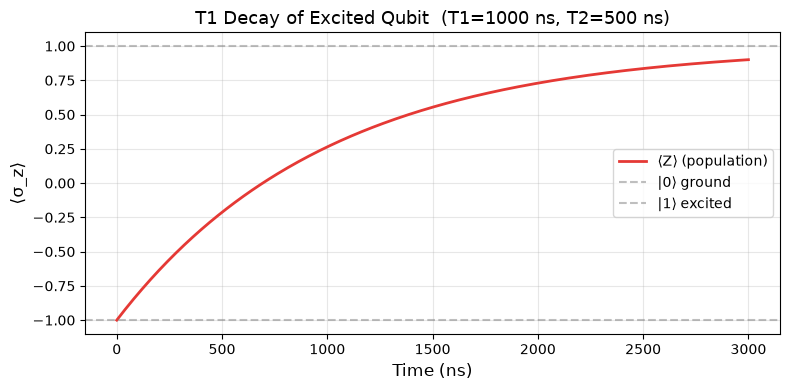

At t=T1=1000 ns, <Z> ~= 0.267 (analytic: 1 - 2/e ~= +0.264)
Measured T2 from coherence decay: 500.0 ns  (labeled T2: 500 ns)


In [2]:
# Simulate free decay of an excited qubit (no drive) to visualize T1,
# and verify the corrected T2 dephasing operator reproduces the labeled T2.
import qutip as qt
import numpy as np
import matplotlib.pyplot as plt

T1 = 1000.0   # ns
T2 = 500.0    # ns
Gamma1 = 1.0 / T1
Gamma2 = 1.0 / T2
Gamma_phi = Gamma2 - Gamma1 / 2

c_ops = [
    np.sqrt(Gamma1) * qt.destroy(2),            # T1: sigma_minus
    np.sqrt(2 * Gamma_phi) * qt.sigmaz() / 2,    # T2*: corrected prefactor
]

# --- T1 decay plot: start in |1>, no drive ---
psi0 = qt.ket2dm(qt.basis(2, 1))
tlist = np.linspace(0, 3000, 300)  # 0 to 3 us
result = qt.mesolve(qt.Qobj([[0,0],[0,0]]), psi0, tlist, c_ops, [qt.sigmaz()])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tlist, result.expect[0], color='#E53935', linewidth=2, label='⟨Z⟩ (population)')
ax.axhline(1,  color='gray', linestyle='--', alpha=0.5, label='|0⟩ ground')
ax.axhline(-1, color='gray', linestyle='--', alpha=0.5, label='|1⟩ excited')
ax.set_xlabel('Time (ns)', fontsize=12)
ax.set_ylabel('⟨σ_z⟩', fontsize=12)
ax.set_title(f'T1 Decay of Excited Qubit  (T1={T1:.0f} ns, T2={T2:.0f} ns)', fontsize=13)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Starting from |1> (<Z>=-1), population relaxes toward |0> (<Z>=+1):
# <Z>(t) = 1 - 2*exp(-t/T1), so <Z>(T1) = 1 - 2/e ~= +0.264
print(f'At t=T1={T1:.0f} ns, <Z> ~= {result.expect[0][100]:.3f} (analytic: 1 - 2/e ~= +0.264)')

# --- T2 verification: start in an equal superposition, measure coherence decay ---
psi_plus = (qt.basis(2, 0) + qt.basis(2, 1)).unit()
tlist2 = np.linspace(0, 500, 2000)
result2 = qt.mesolve(qt.Qobj([[0,0],[0,0]]), psi_plus, tlist2, c_ops, [qt.sigmax(), qt.sigmay()])
coherence = np.abs(result2.expect[0] + 1j * result2.expect[1])
mask = coherence > 1e-6
slope, _ = np.polyfit(tlist2[mask], np.log(coherence[mask]), 1)
print(f'Measured T2 from coherence decay: {-1.0/slope:.1f} ns  (labeled T2: {T2:.0f} ns)')

---
## 3. Why RL? Classical (GRAPE) vs. RL Pulse Optimization

### Classical Approach: GRAPE (Gradient Ascent Pulse Engineering)

GRAPE (Khaneja et al. 2005) treats the pulse as a fixed set of piecewise-constant parameters and optimizes them with gradients against a *known* model of the system. This project implements it in **two configurations** (`grape_baseline.py`):

- **Nominal GRAPE** — optimized against the zero-miscalibration qubit only, with a genuine multi-start search (random restarts over the full [-1,1] range). The *easy* baseline: it never sees the miscalibration distribution, so it isn't a fair comparison for a distribution-trained method on its own.
- **Ensemble (robust) GRAPE** — the same fixed pulse class, optimized for *average* reward over a deterministic 3x3 quadrature grid spanning the same miscalibration distribution RL trains on (standard sample-average approximation of robust optimal control). Still open-loop, still no mid-episode information — but now trained fairly.

### RL Approach: Policy Gradient (PPO)

The RL agent observes the simulator's exact quantum state every timestep and can react to it during training and execution.

```
  Agent ──(Ωx,Ωy)──▶ Qubit ──[8-D state]──▶ Agent
       ◀──reward (fidelity, energy, leakage)──┘
```

**A caveat, not a footnote:** real qubit readout is destructive and takes hundreds of ns to µs — far longer than this 10 ns gate — so a real device cannot provide exact mid-gate state the way this simulator does. Comparing RL only to open-loop GRAPE conflates two separate questions: did RL benefit from training on the *distribution* (which ensemble GRAPE also gets), or from its live (but unrealistic) state access? Section 8 adds a fifth controller — **RL (frozen)**: the trained policy's own waveform, captured once and replayed open-loop — specifically to separate these two explanations. Spoiler: it's overwhelmingly the second one — freezing the policy drops it below GRAPE.

| Property | Nominal GRAPE | Ensemble GRAPE | RL (live) | RL (frozen) |
|----------|-------|-------|----------|----------|
| Needs a known model? | Yes | Yes (+ the uncertainty distribution) | No (model-free) | No |
| Trained/optimized across the miscalibration distribution? | No | Yes | Yes | Yes (inherited) |
| Open- or closed-loop? | Open-loop | Open-loop | "Closed-loop" (see caveat) | Open-loop |
| **Deployable on a real gate-time-scale controller?** | **Yes** | **Yes** | **No** | **Yes** |

**This is the actual, testable thesis of this project**, not just an assertion: Section 8 runs all five controllers under identical physics, across multiple seeds, and reports the real numbers — GRAPE beats RL (frozen), the only *deployable* RL variant.

### Why PPO specifically?

PPO is a **clipped surrogate** policy gradient method that prevents destructively large policy updates:

$$L^{\text{CLIP}}(\theta) = \hat{\mathbb{E}}_t \left[ \min\left( r_t(\theta)\hat{A}_t, \text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)\hat{A}_t \right) \right]$$

This stability matters here because the reward signal is sparse (the fidelity bonus only arrives at the last step of each episode) and the physics is stiff (leakage and decoherence both punish overly aggressive exploration).

---
## 4. The Markov Decision Process (MDP) Formulation

### State Space  $s_t \in [-1,1]^8$

A **generalized Bloch vector** — the minimal sufficient statistic for a 3-level density matrix (8 real numbers for $3^2-1=8$ degrees of freedom): populations $P_1,P_2$ ($P_0=1-P_1-P_2$ is implicit) plus the real/imaginary parts of the 01, 12, and 02 coherences:
$$s_t = [P_1, P_2, \mathrm{Re}\rho_{01}, \mathrm{Im}\rho_{01}, \mathrm{Re}\rho_{12}, \mathrm{Im}\rho_{12}, \mathrm{Re}\rho_{02}, \mathrm{Im}\rho_{02}]$$

Critically, the state does **not** include the episode's hidden detuning or amplitude error (below) — the agent can only infer their effect from how $s_t$ evolves.

**Caveat:** $s_t$ is read directly off the noiseless simulator density matrix — exact populations and coherences, no measurement noise or backaction. A real qubit cannot produce this mid-gate (dispersive readout is destructive and takes hundreds of ns to µs, against a 10 ns gate here). This is fine for training in simulation, but "the agent observes and reacts every step" should not be read as a claim that this is a physically realizable feedback scheme — see Section 8.

### Action Space  $a_t = (a_x, a_y) \in [-1, 1]^2$

Two independent quadratures, scaled to physical units:
$$\Omega_x(t) = a_x \cdot \Omega_{\max}, \qquad \Omega_y(t) = a_y \cdot \Omega_{\max}$$
$\Omega_y$ is exactly the DRAG-style leakage-suppression channel — nothing forces the agent to use it, but nothing hides it either. (Section 8 checks whether it actually learns the DRAG relation — it doesn't, and we characterize what it does instead.)

### Bandwidth-limited control

The qubit never sees $(\Omega_x,\Omega_y)$ directly — it sees them passed through a first-order RC filter with time constant $\tau_{\text{AWG}}$ (default 0.5 ns), modeling a real arbitrary-waveform-generator's finite rise time:
$$\Omega_{\text{applied}}[i] = \Omega_{\text{applied}}[i-1] + \left(1-e^{-dt/\tau_{\text{AWG}}}\right)\left(\Omega_{\text{commanded}}[i] - \Omega_{\text{applied}}[i-1]\right)$$
An instantaneous 1 ns piecewise-constant jump is not physically realizable on real control electronics; this makes sure the agent can't rely on one.

### Per-episode miscalibration (hidden)

At the start of each episode, before any action is taken:
$$\Delta \sim \mathcal{N}(0, \sigma_\Delta^2), \qquad g \sim 1 + \mathcal{N}(0, \sigma_g^2)$$
are sampled once and held fixed for that episode ($\sigma_\Delta=0.03$ rad/ns detuning, $\sigma_g=0.05$ amplitude gain, by default). The Hamiltonian actually driving the qubit uses $\Omega\cdot g$ at detuning $\Delta$ — but the agent's observation never includes $\Delta$ or $g$.

### Reward Function

$$r_t = -\lambda\left(\Omega_x(t)^2+\Omega_y(t)^2\right) - \mu P_2(t) + \big[t{=}T\big] F(\rho_T, \lvert1\rangle)$$

- $\lambda=0.01$ (energy penalty), $\mu=1.0$ (leakage penalty) by default
- The leakage penalty is applied **every step**, not just at the end. $P_2$ here is also read directly off the simulator density matrix (same caveat as $s_t$ above) — a dense training signal, not a claim about real-time hardware leakage monitoring — and it helps the agent avoid leakage-inducing pulse shapes throughout the trajectory, not just discover the problem at the final fidelity readout.

### Episode Structure

- **Start**: qubit in $|0\rangle$
- **Steps**: N=10 steps × dt=1 ns = **10 ns gate** (see `SCIENCE.md`, Section 3, for why 10 ns: fidelity here is decoherence- *and* leakage-limited, not simply control-limited)
- **End**: measure fidelity vs. $|1\rangle$ — leaked or undecided population is automatically counted as infidelity, no separate accounting needed. (This is single-input-state transfer fidelity, not full average gate fidelity — see `SCIENCE.md`, Section 3.)

In [3]:
# Verify our environment setup
import sys
sys.path.insert(0, '.')  # ensure local modules are importable

from quantum_env import QuantumPulseEnv
from utils import QUBIT_PARAMS

env = QuantumPulseEnv(n_steps=10, dt=1.0, omega_max=0.35, energy_penalty=0.01,
                       leakage_penalty=1.0, bandwidth_tau=0.5,
                       detuning_std=0.03, amp_error_std=0.05)

print('Environment summary')
print('=' * 40)
print(f'  Observation space : {env.observation_space}')
print(f'  Action space      : {env.action_space}')
print(f'  Gate time         : {env.n_steps * env.dt:.0f} ns')
print(f'  Omega_max         : {env.omega_max:.3f} rad/ns per quadrature')
print(f'  T1 / T2           : {QUBIT_PARAMS["T1"]:.0f} / {QUBIT_PARAMS["T2"]:.0f} ns')
print(f'  Anharmonicity     : {QUBIT_PARAMS["alpha"]:.3f} rad/ns')

# Run one random episode to verify it works
obs, _ = env.reset(seed=0)
print(f'\nInitial observation (|0>, all zero): {obs}')
print(f'This episode hidden detuning: {env._episode_detuning:+.4f} rad/ns')
print(f'This episode hidden amp gain: {env._episode_amp_gain:.4f}')

total_reward = 0
for _ in range(env.n_steps):
    action = env.action_space.sample()
    obs, reward, done, _, info = env.step(action)
    total_reward += reward

print(f'\nFinal observation (random policy): {obs}')
print(f'Final fidelity (random policy)    : {info["fidelity"]:.4f}')
print(f'Final leakage P2 (random policy)  : {info["leakage"]:.4f}')
print(f'Total reward                       : {total_reward:.4f}')

Environment summary
  Observation space : Box(-1.0, 1.0, (8,), float32)
  Action space      : Box(-1.0, 1.0, (2,), float32)
  Gate time         : 10 ns
  Omega_max         : 0.350 rad/ns per quadrature
  T1 / T2           : 1000 / 500 ns
  Anharmonicity     : -1.571 rad/ns

Initial observation (|0>, all zero): [0. 0. 0. 0. 0. 0. 0. 0.]
This episode hidden detuning: +0.0038 rad/ns
This episode hidden amp gain: 0.9934

Final observation (random policy): [ 0.00163386  0.00826748 -0.03454217  0.00828111 -0.00282402  0.00181649
  0.05922561 -0.06715459]
Final fidelity (random policy)    : 0.0016
Final leakage P2 (random policy)  : 0.0083
Total reward                       : -0.0559


---
## 5. Environment Deep Dive

### How `quantum_env.py`'s `step()` works

```python
def step(self, action):
    # 1. Decode action -> commanded physical amplitudes
    cmd_x, cmd_y = action * self.omega_max

    # 2. Bandwidth-limit: qubit sees a lagged version of the command
    applied_x, applied_y = self._apply_bandwidth_filter(cmd_x, cmd_y)

    # 3. Unknown-to-the-agent amplitude-calibration error
    true_x, true_y = applied_x * self._episode_amp_gain, applied_y * self._episode_amp_gain

    # 4. Integrate the Lindblad equation for dt nanoseconds
    H = [H0, [Hx, true_x], [Hy, true_y]]        # H0 built with this episode's hidden detuning
    rho = mesolve(H, rho, [0, dt], c_ops).states[-1]

    # 5. Compute reward: energy + leakage penalty every step, fidelity bonus at the end
    reward = -energy_penalty * (cmd_x**2 + cmd_y**2) - leakage_penalty * P2
    if done:
        reward += fidelity(rho, |1>)

    return obs, reward, done, info
```

### The Markovian assumption

The Lindblad equation assumes **Markovian (memoryless) noise** — an excellent approximation for transmon qubits at millikelvin temperatures, where the phonon-bath correlation time (~ps) is far shorter than the gate time (~10 ns). This is also why the 8-D generalized Bloch vector is a *sufficient* state for the MDP: no memory of earlier steps is needed to predict what happens next, given the current density matrix.

### What the agent *cannot* see

Three things are real to the physics but invisible to the observation: the per-episode detuning $\Delta$, the per-episode amplitude gain $g$, and the raw commanded amplitude before bandwidth filtering. The agent can only work with what a real experimentalist could actually measure mid-circuit: the qubit's own state.

In [4]:
# Visualize the Hamiltonians and collapse operators
from utils import build_hamiltonians, build_collapse_operators, QUBIT_PARAMS
import qutip as qt

H0, Hx, Hy = build_hamiltonians(QUBIT_PARAMS)
c_ops = build_collapse_operators(QUBIT_PARAMS)

print('H0 (drift: detuning + anharmonicity), diagonal since Delta=0 by default:')
print(H0)
print('\nHx (I control) -- note the sqrt(2) off-diagonal element coupling |1> and |2>:')
print(Hx)
print('\nHy (Q control, the DRAG-like channel):')
print(Hy)
print(f'\nNumber of collapse operators: {len(c_ops)}')
print('c_ops[0] -- T1 amplitude damping (a):')
print(c_ops[0])
print('c_ops[1] -- T2* dephasing (corrected prefactor, sqrt(2*Gamma_phi)*n/2):')
print(c_ops[1])

H0 (drift: detuning + anharmonicity), diagonal since Delta=0 by default:
Quantum object: dims = [[3], [3]], shape = (3, 3), type = oper, isherm = True
Qobj data =
[[ 0.      0.      0.    ]
 [ 0.      0.      0.    ]
 [ 0.      0.     -1.5708]]

Hx (I control) -- note the sqrt(2) off-diagonal element coupling |1> and |2>:
Quantum object: dims = [[3], [3]], shape = (3, 3), type = oper, isherm = True
Qobj data =
[[0.         0.5        0.        ]
 [0.5        0.         0.70710678]
 [0.         0.70710678 0.        ]]

Hy (Q control, the DRAG-like channel):
Quantum object: dims = [[3], [3]], shape = (3, 3), type = oper, isherm = True
Qobj data =
[[0.+0.j         0.-0.5j        0.+0.j        ]
 [0.+0.5j        0.+0.j         0.-0.70710678j]
 [0.+0.j         0.+0.70710678j 0.+0.j        ]]

Number of collapse operators: 2
c_ops[0] -- T1 amplitude damping (a):
Quantum object: dims = [[3], [3]], shape = (3, 3), type = oper, isherm = False
Qobj data =
[[0.         0.03162278 0.        ]
 [0.

---
## 6. Training a PPO Agent (Short Demo)

The full training run (200 k steps) takes ~25-30 min on CPU (3-level physics is slower per step than the 2-level model). Here we run a **short demo** (5 000 steps) just to verify the pipeline. Use `train.py` for full training.

### PPO Hyperparameters

| Parameter | Value | Rationale |
|-----------|-------|----------|
| `n_steps` | 256 | Rollout buffer length (independent of the 10-step episode length; must stay >= `batch_size`) |
| `batch_size` | 64 | Mini-batch for updates |
| `n_epochs` | 10 | Gradient steps per rollout |
| `clip_range` | 0.2 | PPO clip ε |
| `ent_coef` | 0.01 | Entropy bonus for exploration |
| `learning_rate` | 3e-4 | Adam optimizer |
| Network | MLP [64, 64] | Sufficient for the 8-D state space |

In [5]:
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from quantum_env import QuantumPulseEnv

# Create environment (2D action: I and Q quadratures)
env = Monitor(QuantumPulseEnv(n_steps=10, dt=1.0, omega_max=0.35, energy_penalty=0.01,
                               leakage_penalty=1.0, bandwidth_tau=0.5,
                               detuning_std=0.03, amp_error_std=0.05))

# Build PPO agent
# Rollout buffer (n_steps below, SB3's own hyperparameter -- unrelated to the
# environment's episode length) must be >= batch_size; with a short 10-step
# episode, 4 episodes' worth (40) would be smaller than batch_size=64, so we
# use a fixed 256 instead (same fix applied in train.py).
model = PPO(
    policy='MlpPolicy',
    env=env,
    learning_rate=3e-4,
    n_steps=256,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    clip_range=0.2,
    ent_coef=0.01,
    policy_kwargs=dict(net_arch=[64, 64]),
    seed=42,
    verbose=0,
)

print('PPO agent created!')
print(f'Action space (Omega_x, Omega_y): {env.action_space}')
print(f'Observation space (8-D generalized Bloch vector): {env.observation_space}')
print(f'Policy architecture: {model.policy}')
print(f'Total parameters: {sum(p.numel() for p in model.policy.parameters()):,}')

PPO agent created!
Action space (Omega_x, Omega_y): Box(-1.0, 1.0, (2,), float32)
Observation space (8-D generalized Bloch vector): Box(-1.0, 1.0, (8,), float32)
Policy architecture: ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=2, bias=True)
  (value_net): Lin

In [6]:
# Short training demo — 5000 timesteps (~100 episodes)
# NOTE: For real results, run: python train.py --timesteps 200000

from stable_baselines3.common.callbacks import BaseCallback
import numpy as np

class FidelityTracker(BaseCallback):
    def __init__(self):
        super().__init__()
        self.fidelities = []
        self.episode_rewards = []
        self._ep_reward = 0.0

    def _on_step(self):
        self._ep_reward += float(self.locals['rewards'][0])
        if self.locals['dones'][0]:
            info = self.locals['infos'][0]
            if 'fidelity' in info:
                self.fidelities.append(info['fidelity'])
            self.episode_rewards.append(self._ep_reward)
            self._ep_reward = 0.0
        return True

tracker = FidelityTracker()

print('Training for 5000 timesteps (demo)...')
model.learn(total_timesteps=5000, callback=tracker, progress_bar=True)
print('Demo training complete!')

if tracker.fidelities:
    print(f'\nFidelity over training:')
    print(f'  First 10 episodes mean : {np.mean(tracker.fidelities[:10]):.4f}')
    print(f'  Last  10 episodes mean : {np.mean(tracker.fidelities[-10:]):.4f}')
    print(f'  (Run python train.py for full 200k timestep training)')

Output()

Training for 5000 timesteps (demo)...


Demo training complete!

Fidelity over training:
  First 10 episodes mean : 0.1926
  Last  10 episodes mean : 0.8386
  (Run python train.py for full 200k timestep training)


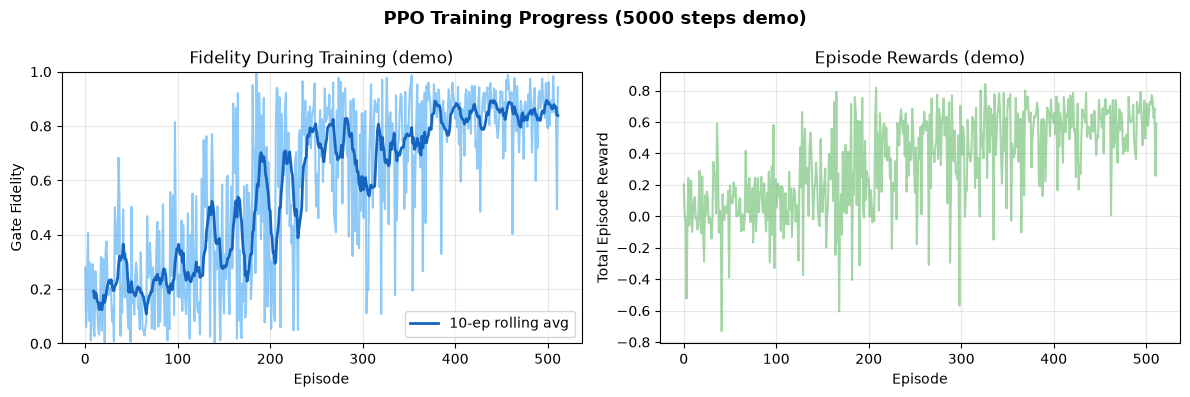

In [7]:
# Plot training progress
import matplotlib.pyplot as plt
import numpy as np

if tracker.fidelities:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(tracker.fidelities, alpha=0.6, color='#42A5F5')
    if len(tracker.fidelities) >= 10:
        rolling = np.convolve(tracker.fidelities, np.ones(10)/10, mode='valid')
        ax1.plot(np.arange(9, len(tracker.fidelities)), rolling,
                 color='#1565C0', linewidth=2, label='10-ep rolling avg')
    ax1.set_xlabel('Episode')
    ax1.set_ylabel('Gate Fidelity')
    ax1.set_title('Fidelity During Training (demo)')
    ax1.set_ylim([0, 1])
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(tracker.episode_rewards, alpha=0.6, color='#66BB6A')
    ax2.set_xlabel('Episode')
    ax2.set_ylabel('Total Episode Reward')
    ax2.set_title('Episode Rewards (demo)')
    ax2.grid(True, alpha=0.3)

    plt.suptitle('PPO Training Progress (5000 steps demo)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

---
## 7. Evaluating the Agent: I/Q Pulse, Leakage, and Bloch Sphere

After training (or using the demo model), we can:
1. Run one deterministic episode with the trained policy
2. Record the pulse quadratures $\Omega_x(t), \Omega_y(t)$
3. Re-simulate the trajectory and plot level populations (leakage) + the 0-1 subspace Bloch sphere

In [8]:
# Evaluate the demo-trained agent
from quantum_env import QuantumPulseEnv
from utils import plot_pulse_and_bloch
import numpy as np

eval_env = QuantumPulseEnv(n_steps=10, dt=1.0, omega_max=0.35, energy_penalty=0.01,
                            leakage_penalty=1.0, bandwidth_tau=0.5,
                            detuning_std=0.03, amp_error_std=0.05)

obs, _ = eval_env.reset(seed=7)
done = False
info = {}

while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = eval_env.step(action)
    done = terminated or truncated

fidelity = info.get('fidelity', 0.0)
pulse_x = np.array(info.get('pulse_x', []))
pulse_y = np.array(info.get('pulse_y', []))

print(f'Demo agent fidelity: {fidelity:.4f}  (leakage: {info["leakage"]:.4f})')
print(f'  (Note: this demo only trained for 5000 steps on the full task --')
print(f'   leakage, bandwidth limit, and hidden miscalibration all active --')
print(f'   so do not expect the full >0.99 nominal-condition target from this')
print(f'   short demo alone.)')
print(f'  (Full training at 200k steps -- see train.py and SCIENCE.md for verified numbers)')

# Simulate populations + 0-1 subspace Bloch trajectory
populations, bloch01 = eval_env.get_full_trajectory(
    pulse_x, pulse_y, detuning=info['detuning'], amp_gain=info['amp_gain'])
print(f'Populations shape: {populations.shape}  (n_steps+1, 3) = [P0, P1, P2]')
print(f'Start populations: {populations[0]}')
print(f'End   populations: {populations[-1]}  (P2 is leakage)')

Demo agent fidelity: 0.9788  (leakage: 0.0011)
  (Note: this demo only trained for 5000 steps on the full task --
   leakage, bandwidth limit, and hidden miscalibration all active --
   so do not expect the full >0.99 nominal-condition target from this
   short demo alone.)
  (Full training at 200k steps -- see train.py and SCIENCE.md for verified numbers)
Populations shape: (11, 3)  (n_steps+1, 3) = [P0, P1, P2]
Start populations: [1. 0. 0.]
End   populations: [0.02008152 0.97884536 0.00107312]  (P2 is leakage)


C:\Users\Johnny\Desktop\Quantum-Control-Project\utils.py:261: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


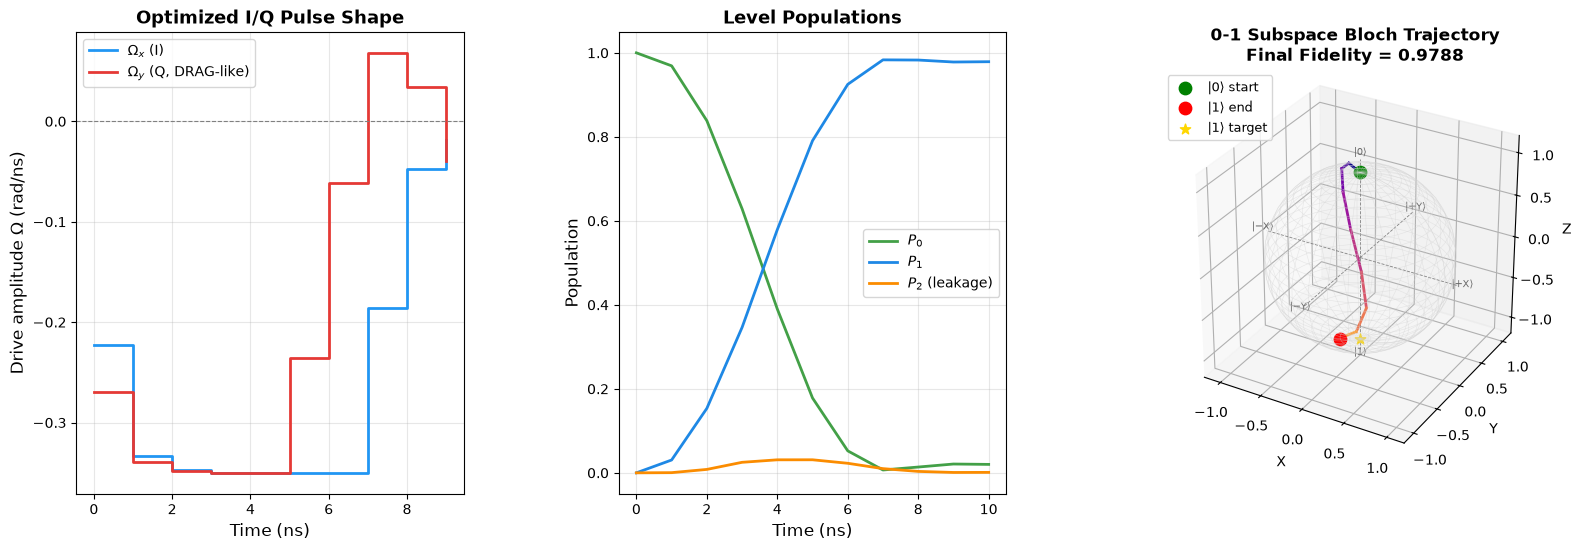

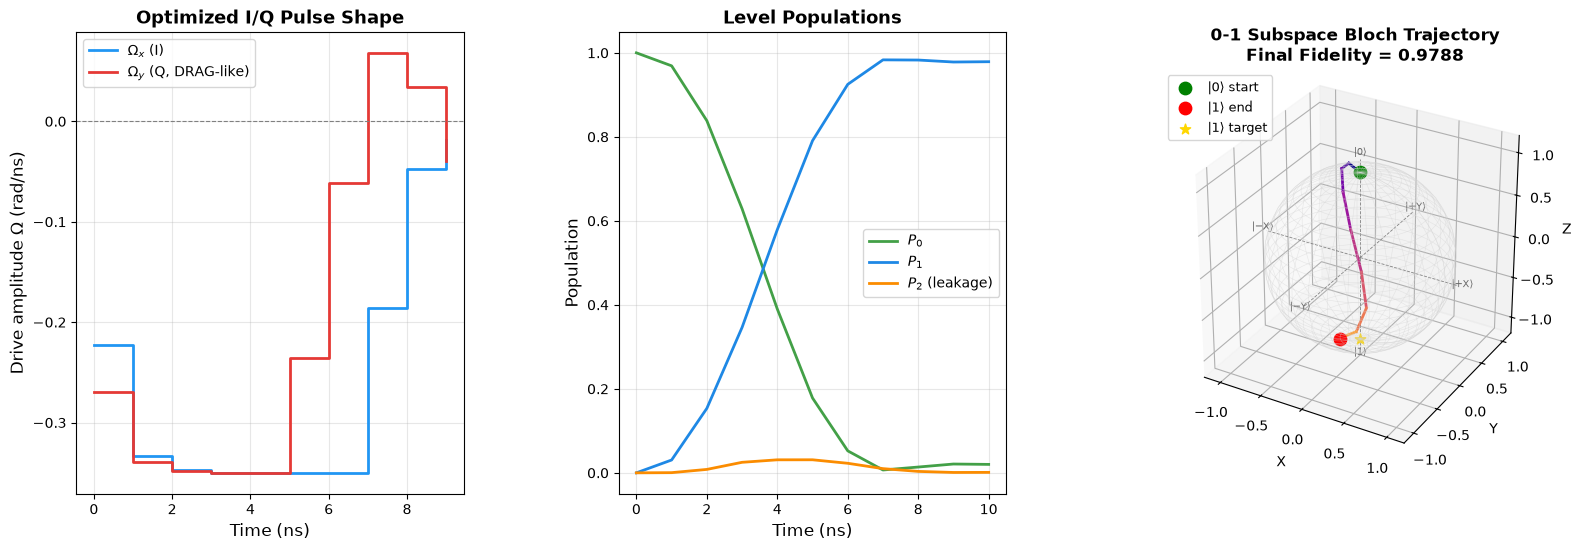

In [9]:
# Plot I/Q pulse shape + level populations + Bloch sphere trajectory
from utils import plot_pulse_and_bloch

plot_pulse_and_bloch(
    amplitudes_x=pulse_x,
    amplitudes_y=pulse_y,
    populations=populations,
    bloch01=bloch01,
    dt=1.0,
    fidelity=fidelity,
)

---
## 8. Five Controllers, One Physics: GRAPE, Ensemble-GRAPE, RL, and the Frozen-Policy Mechanism Test

Comparing RL only against nominal GRAPE (optimized for a perfectly-known qubit) isn't fair to GRAPE, and even a fair GRAPE comparison can't tell you *why* RL wins if it does. Two questions, two extra controllers:

- **Is a robustness gap just about training on the right distribution?** Ensemble/robust GRAPE — optimized for *average* reward over a fixed grid spanning the same miscalibration distribution RL trains on — is still open-loop, still no mid-episode information, but now trained fairly. If it matches RL, the answer is yes. (It doesn't — it barely beats nominal GRAPE.)
- **Or is RL exploiting live state access no open-loop method could ever use?** RL (frozen) — the trained policy's own waveform, captured from one nominal rollout and replayed open-loop, exactly like GRAPE — answers this directly. If RL (live) collapses toward (or below) GRAPE once frozen, that's the answer. (It does: RL (frozen) loses to nominal GRAPE.)

**The headline result:** among the controllers a real gate-time-scale controller could actually run, GRAPE wins. RL (live)'s apparent edge depends on mid-episode information no real qubit readout can provide inside a 10 ns gate — the one exception is leakage, which RL (frozen) keeps at RL (live)'s level even after losing the fidelity edge.

The full version of this comparison (`seed_study.py`, 5 RL training seeds x 5 GRAPE/ensemble-GRAPE optimization seeds, paired evaluation draws, paired significance tests) is what `SCIENCE.md` Section 7 reports. Below is a small, fast, *real* (not illustrative/fake) single-seed version of the same five-controller procedure, using this notebook's lightly-trained demo model, so you can see the mechanism end-to-end without leaving the notebook.

> **This is a fast demo, not the reported result.** The cell below runs GRAPE and ensemble-GRAPE at reduced settings (`n_restarts=1`, `maxiter=6`) so it finishes in ~1-2 minutes instead of the full study's cost, and uses this notebook's lightly-trained (5000-step) demo policy instead of a fully-trained one. **The numbers you see here will not match README.md or SCIENCE.md, Section 7** — those come from `seed_study.py`: 5 fully-trained RL seeds (200,000 timesteps each), full-budget GRAPE/ensemble-GRAPE optimization, and 150 paired evaluation draws. Treat this cell as a demonstration of the *mechanism* (identical physics, identical paired draws, five controllers, the frozen-policy check), not as a source of citable numbers.

In [10]:
from grape_baseline import (
    run_grape, run_ensemble_grape, naive_pulse, sample_draws, evaluate_on_draws, distill_policy,
)
import argparse
import numpy as np

# Build a small args namespace matching this notebook's environment settings.
# n_restarts=1 (no random restart): the full study (seed_study.py, Section 7 of
# SCIENCE.md) found that across all 5 optimization seeds, every random restart
# was beaten by the single physics-informed (naive pi-pulse) seeded init -- so
# this demo skips the restarts that never won and keeps only the useful one.
# maxiter is capped low because ensemble-GRAPE's objective averages over 9
# miscalibration draws per evaluation, and L-BFGS-B's finite-difference gradient
# needs ~20 evaluations per iteration -- a few iterations already gets within
# ~0.001 fidelity of the fully-converged result (see SCIENCE.md, Section 7.2).
grape_args = argparse.Namespace(
    n_steps=10, dt=1.0, omega_max=0.35, leakage_pen=1.0, energy_pen=0.01,
    bandwidth_tau=0.5, detuning_std=0.03, amp_error_std=0.05,
    n_restarts=1, maxiter=6, restart_seed=0,
)

print('Optimizing small nominal-GRAPE and ensemble-GRAPE pulses (real, but fast: ~1-2 min)...')
naive_actions = naive_pulse(grape_args)
grape_actions, grape_nominal_fid, grape_nominal_leak = run_grape(grape_args)
ens_actions, ens_nominal_fid, ens_nominal_leak = run_ensemble_grape(grape_args)

# The mechanism test: freeze this notebook's demo policy into a fixed,
# open-loop pulse from one nominal rollout.
frozen_actions = distill_policy(model, grape_args)

# Evaluate all controllers on the SAME paired miscalibration draws -- the
# apples-to-apples comparison.
n_eval_demo = 30
draws = sample_draws(n_eval_demo, grape_args.detuning_std, grape_args.amp_error_std, seed=42)
naive_fids = evaluate_on_draws(naive_actions, grape_args, draws, is_rl=False)
grape_fids = evaluate_on_draws(grape_actions, grape_args, draws, is_rl=False)
ens_fids = evaluate_on_draws(ens_actions, grape_args, draws, is_rl=False)
rl_fids = evaluate_on_draws(model, grape_args, draws, is_rl=True)
frozen_fids = evaluate_on_draws(frozen_actions, grape_args, draws, is_rl=False)

print(f'\n{"Controller":24s}{"Nominal":>10s}{"Robust mean":>14s}{"Robust std":>12s}')
print(f'{"Naive pulse":24s}{"--":>10s}{naive_fids.mean():14.4f}{naive_fids.std():12.4f}')
print(f'{"GRAPE (nominal)":24s}{grape_nominal_fid:10.4f}{grape_fids.mean():14.4f}{grape_fids.std():12.4f}')
print(f'{"Ensemble-GRAPE":24s}{ens_nominal_fid:10.4f}{ens_fids.mean():14.4f}{ens_fids.std():12.4f}')
print(f'{"RL (live)":24s}{"--":>10s}{rl_fids.mean():14.4f}{rl_fids.std():12.4f}')
print(f'{"RL (frozen)":24s}{"--":>10s}{frozen_fids.mean():14.4f}{frozen_fids.std():12.4f}')
print('\n(This notebook\'s model only trained for 5000 demo timesteps, on the full')
print(' task -- leakage, bandwidth limit, hidden miscalibration all active -- so')
print(' absolute numbers here will not match SCIENCE.md Section 7\'s fully-trained,')
print(' 5-seed result. The mechanism this cell demonstrates is what matters:')
print(' identical physics, identical paired draws, five controllers -- including')
print(' the frozen-policy check of whether RL (live) actually needs its live state')
print(' access to win.)')

Optimizing small nominal-GRAPE and ensemble-GRAPE pulses (real, but fast: ~1-2 min)...
[grape] Optimizing 20 params vs. NOMINAL qubit (1 restarts, maxiter=6)...


  [grape:seeded] final objective (-reward) = -0.881748
[grape] Best nominal fidelity: 0.9890  leakage: 0.0053  reward: 0.8817
[ensemble-grape] Optimizing 20 params vs. 9-point ensemble (1 restarts, maxiter=6)...


  [ensemble-grape:seeded] final objective (-reward) = -0.873044


[ensemble-grape] Ensemble-mean fidelity: 0.9797  leakage: 0.0049



Controller                 Nominal   Robust mean  Robust std
Naive pulse                     --        0.9566      0.0169
GRAPE (nominal)             0.9890        0.9805      0.0085
Ensemble-GRAPE              0.9797        0.9809      0.0086
RL (live)                       --        0.9781      0.0024
RL (frozen)                     --        0.9711      0.0135

(This notebook's model only trained for 5000 demo timesteps, on the full
 task -- leakage, bandwidth limit, hidden miscalibration all active -- so
 absolute numbers here will not match SCIENCE.md Section 7's fully-trained,
 5-seed result. The mechanism this cell demonstrates is what matters:
 identical physics, identical paired draws, five controllers -- including
 the frozen-policy check of whether RL (live) actually needs its live state
 access to win.)


---
## 9. Next Steps & Extensions

This project's core claim rests on five controllers and a mechanism test (Section 8), not just a trained agent — and the headline result is that GRAPE beats every deployable RL policy, with RL's apparent edge traced to information a real gate-time-scale controller can't have. Natural extensions from here:

### Physics Extensions
- **Two-qubit gates**: Extend to a coupled 2-transmon system and optimize a CNOT/CZ gate.
- **1/f flux noise**: Replace the fixed per-episode detuning with a slowly-drifting (correlated-in-time) detuning process, closer to real qubit frequency noise spectra.
- **Full transmon charge dispersion**: Move beyond the fixed-anharmonicity truncated-oscillator model to a more complete transmon Hamiltonian.
- **Average gate fidelity**: Test multiple input states (not just |0⟩) and compute a proper average-gate/process fidelity, rather than a single state-transfer fidelity.

### ML Extensions
- **SAC (Soft Actor-Critic)**: Better sample efficiency than PPO for continuous actions.
- **Model-based RL**: Learn a neural-network emulator of the QuTiP simulator for faster rollouts.
- **A better-resourced ensemble GRAPE**: Match its compute budget to RL's training cost (more quadrature points, more iterations) and see whether the (already small) gap to nominal GRAPE narrows further.
- **Realistic partial observability**: Replace exact mid-gate state access with something closer to what real hardware could provide (e.g. no intra-gate observation at all, only inter-shot calibration feedback), to test whether a *realizable* form of closed-loop control could still beat GRAPE — the frozen-policy result (Section 8) says the current, fully-informed version can't.

### Hardware Integration
- Replace the QuTiP simulator with a **real QPU backend** (e.g., IBM Quantum via Qiskit Pulse) for hardware-in-the-loop RL.
- Use **randomized benchmarking** as the reward signal instead of analytical fidelity.

---

### Run Everything

```bash
# Full RL training (~200k steps, ~25-30 min on CPU)
python train.py --timesteps 200000

# Monitor with TensorBoard
tensorboard --logdir logs/

# Evaluate the trained agent (fidelity, leakage, under miscalibration)
python evaluate.py

# Quick single-seed 5-controller check (naive / GRAPE / ensemble-GRAPE / RL live / RL frozen)
python grape_baseline.py --model models/best_model.zip

# DRAG-correlation detector: self-test + check across all trained policies
python drag_check.py --model-root models_seedstudy --n-seeds 5

# The real comparison: 5 seeds, paired evaluation draws, mean +- std across seeds, statistics
python seed_study.py --n-seeds 5 --timesteps 200000
```